# Supplemental Figure 5, Panel G

Effect of BAFinh on IFN-g induced nascent transcription increases at genes. Includes
- Density plot of log2FC nascent transcription, BAFinh + IFN-gamma vs IFN-gamma for induced genes as well as baseline expression-matched control genes
- Barplot enumerating numbers of genes within induced and control set that are significantly (FDR < 0.05, log2FC < -log2(1.5)) downregulated, nominally downregulated (log2FC < 0) and not changing

*Output: PanelG.pdf*

# Setup

In [4]:
library(tidyverse)
library(here)
library(pheatmap)
library(patchwork)
here::i_am("figures/SuppFig5/PanelG/PanelG.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank()))

sessionInfo()

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] patchwork_1.3.0 pheatmap_1.0.12 here_1.0.2      lubridate_1.9.4
 [5] forcats_1.0.0   stringr_1.5.1   dplyr_1.1.4     purrr_1.0.2    
 [9] readr_2.1.5     tidyr_1.3.1     tibble_3.2.1    ggplot2_3.5.2  
[13] tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] RColorBrewer_1.1-

# load data

In [3]:
# PRO-seq DEGs, IFN-gamma vs vehicle 
ifn <- read.delim(
    here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "PROseq", "PRO_DEGs_IFN_Veh.tsv"),
    sep='\t')
ifn_up <- which(ifn$change=="up")

# PRO-seq DEGs, BAFinh + IFN-gamma vs IFN-gamma 
bafinh_ifn <- read.delim(
    here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "PROseq", "PRO_DEGs_BAFinh_IFN_IFN.tsv"),
    sep='\t')

# PRO-seq DEGs, BAFinh vs vehicle
bafinh <- read.delim(
    here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "PROseq", "PRO_DEGs_BAFinh_Veh.tsv"),
    sep='\t')

# gene-level metadata for counts data (incl. gene length)
gene_metadata <- read.delim(
    here("inputs","DEGs","GM12878","BAFinh_stimulus","PROseq","PRO_genes_metadata.tsv"),
    sep='\t')

# Gene-level PRO-seq counts
counts <- read.delim(
    here("inputs","DEGs","GM12878","BAFinh_stimulus","PROseq","PRO_counts_genes.tsv"),
         sep='\t')
# normalize by transcript length 
rpk <- apply(counts, 2, function(x) 1000*x/gene_metadata$width)
# normalize by read depth 
tpm <- apply(rpk, 2, function(x) 1000000*x/sum(x)) %>% data.frame()

# generate expression-matched controls for IFN-inducible genes 

In [5]:
match_cols <- c("veh_IFN_1", "veh_IFN_2", "veh_IFN_3")
k <- 5 # number of controls per induced gene

expr <- log2(rowMeans(tpm[, match_cols, drop = FALSE]) + 1)

targets <- which(ifn$gene %in% ifn$gene[ifn_up]  & is.finite(expr)) # set of induced genes
pool <- which(!ifn$gene %in% ifn$gene[ifn_up]  & is.finite(expr)) # all other genes (pool from which to pick controls)
stopifnot(length(pool) >= k)

matches <- do.call(rbind, lapply(targets, function(i) {
    j <- pool[order(abs(expr[pool] - expr[i]))[seq_len(k)]] # top 5 genes with most simular expression to induced gene
    data.frame(
        target = ifn$gene[i],
        control = ifn$gene[j],
        target_logTPM = expr[i],
        control_logTPM = expr[j]
  )
}))

control_genes <- unique(matches$control)

# generate plots

Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”
`summarise()` has grouped output by 'set'. You can override using the `.groups`
argument.
Saving 7 x 3 in image


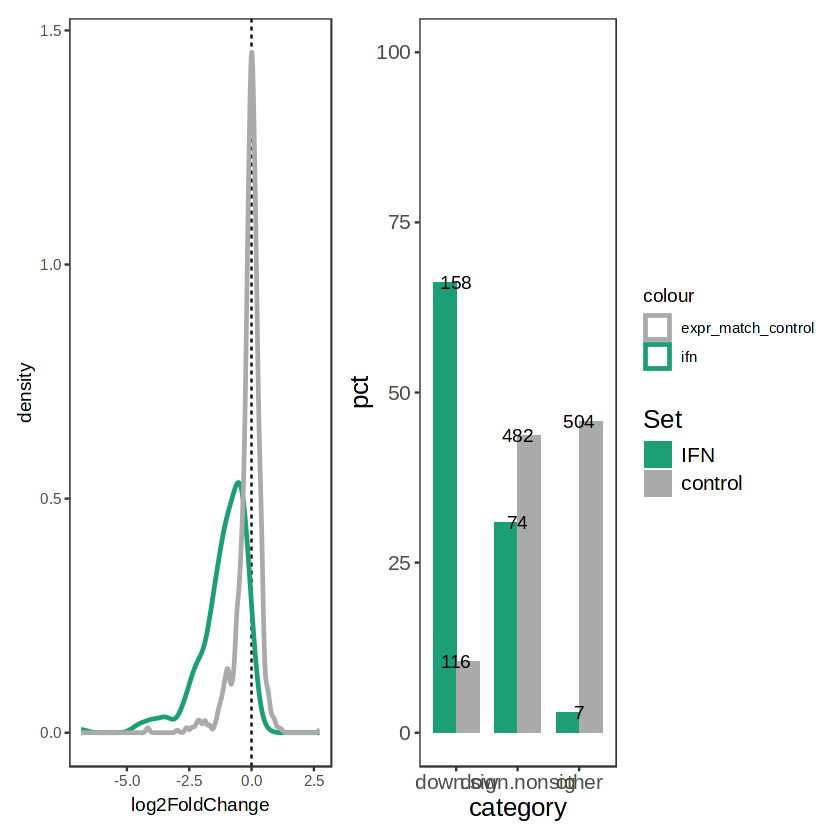

In [8]:
p1 <- bafinh_ifn %>% filter(gene %in% ifn[ifn_up,"gene"]) %>%
    ggplot(aes(x=log2FoldChange)) + 
    geom_vline(xintercept=0, linetype=2) + 
    geom_density(linewidth=1, aes(color="ifn")) +
    geom_density(data=bafinh_ifn[bafinh_ifn$gene %in% control_genes,], aes(x=log2FoldChange, color="expr_match_control"), linewidth=1) +
    #geom_density(data=bafinh_ifn[bafinh_ifn$gene %in% dex_ss_up,], aes(x=log2FoldChange, color="dex_ind_control"), linewidth=1) +
    scale_color_manual(values=c("ifn"="#1c9e77", "expr_match_control"="#aaaaaa"))#, "dex_ind_control"="#555555"))

p2 <- bafinh_ifn%>% 
    group_by(set=case_when(gene %in% ifn[ifn_up,"gene"] ~ "IFN",
                           gene %in% control_genes ~ "control",
                           TRUE ~ NA),
            cat=case_when(change=="down" & log2FoldChange < 0 ~ "down.sig",
                          change!="down" & log2FoldChange < 0 ~ "down.nonsig",
                          TRUE ~ "other")) %>%
    na.omit() %>%
    summarize(n=n(), .groups="drop") %>%
    group_by(set) %>% 
    summarize(set,cat,n,pct=100*n/sum(n)) %>%
    ggplot(aes(x=factor(cat, levels=c("down.sig", "down.nonsig", "other")), y=pct, fill=factor(set, levels=c("IFN", "control")))) + geom_col(width=.75, position=position_dodge())+
    theme(text=element_text(size=15)) + 
    geom_text(aes(label=n)) + ylim(0,100) +
    xlab("category") +
    scale_fill_manual(values=c("IFN"="#1c9e77", "control"="#aaaaaa"), name="Set")


(p1 | p2 ) + plot_layout(guides="collect", widths=c(1,.75))
ggsave("PanelG.pdf", height=3)

In [6]:
str(control_genes)
str(targets)

 chr [1:1102] "RPS15" "HSP90AA1" "RPS27A" "CYBC1" "DENND2D" "STIMATE" ...
 int [1:239] 4 90 106 107 121 229 233 235 236 237 ...
